# Wavelength band-subset ablations — OxHyp / EuroCrops / BNETD

Two related ablations that restrict each encoder's input to a subset of spectral bands instead of
the full sensor band set, testing whether wavelength-conditioned hyperspectral encoders actually
exploit the wavelength metadata they're given, rather than treating it as decoration.

- **Part 1 — semantic spectral regions**: restrict input to a domain-meaningful contiguous region —
  **RGB** (the sensor's canonical R/G/B bands), **VIS** (380–700nm), **VNIR** (380–1000nm, the real
  Silicon-detector hardware range), or **SWIR** (1000–2600nm) — compared against the full-band
  baseline, per dataset, per encoder.
- **Part 2 — random band subsets**: for each of the same four band **counts**, three independent
  random draws (fixed seeds 0/1/2, uniform without replacement across the full spectrum — not
  necessarily from that group's own wavelength range), compared against full-band the same way. Also
  shows *which* bands each draw actually picked.
- **Part 3 — semantic vs. random, matched by band count**: the comparison that isolates band *count*
  from band *identity* — does the real region actually beat an arbitrary same-size subset?

**Scope**: `oxhyperminerals_emit_l2a` (EMIT, mineral segmentation), `eurocrops` (EnMAP, crop-type
segmentation), `bnetd` (EnMAP, Ivorian forest-type segmentation). Five wavelength-conditioned
encoders (DOFA-B, DOFAv2-B, Copernicus-FM-B, Panopticon-B, CARL) with `mlp_fusion_head`, frozen
backbone / linear probe only — the only backbones in this benchmark that support a `wave_list`
override making them genuinely channel-count-agnostic. UniverSat-B (its own `ConvSegmentor`
decoder/path, native image size) only has the random-subset ablation, shown at the end of Part 2.

**Why logs, not `sacct`/checkpoint existence**: same rule as `benchmark_results.ipynb` — only the
`Best ckpt path:` line `train.py` prints after `trainer.test()` finishes is treated as genuine
completion.

**Metric note**: `oxhyperminerals_emit_l2a` uses `MultiLabelSegmentationModule` (multi-hot mineral
labels) and logs `test_MeanIoU`/`test_OverallAccuracy`, not `test_MulticlassJaccardIndex`/
`test_MulticlassAccuracy` like the single-label tasks. The parser tries both name variants per metric
so this falls through automatically.

In [1]:
from __future__ import annotations

import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
import csv as csv_module

## Configuration

Mirrors the exact naming scheme used by `run_wavelength_ablation.sh` / `run_random_band_ablation.sh`
/ `run_random_band_universat.sh`. If any of those scripts' naming changes, update it here too.

In [2]:
DISK_ROOT = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments/hsi-bench")
REPO_ROOT = Path.cwd().parent  # notebooks/ -> repo root

TASKS = ["oxhyperminerals_emit_l2a", "eurocrops", "bnetd"]
TASK_LABELS = {
    "oxhyperminerals_emit_l2a": "OxHyp",
    "eurocrops": "EuroCrops",
    "bnetd": "BNETD",
}
TASK_SENSOR = {
    "oxhyperminerals_emit_l2a": "emit",
    "eurocrops": "enmap",
    "bnetd": "enmap",
}

BACKBONES = ["dofa_b", "dofav2_b", "copernicus_fm_b", "panopticon_b", "carl"]
BACKBONE_LABELS = {
    "dofa_b": "DOFA-B",
    "dofav2_b": "DOFAv2-B",
    "copernicus_fm_b": "Copernicus-FM-B",
    "panopticon_b": "Panopticon-B",
    "carl": "CARL",
    "universat_b": "UniverSat-B",  # Part 2 only -- different decoder/path, see note there.
}
WEIGHT_INIT = {
    "dofa_b": "dofa_pretrained",
    "dofav2_b": "dofav2_pretrained",
    "copernicus_fm_b": "copernicus_fm_pretrained",
    "panopticon_b": "panopticon_pretrained",
    "carl": "carl_pretrained",
}

GROUPS = ["full", "rgb", "vis", "vnir", "swir"]
GROUP_LABELS = {"full": "Full", "rgb": "RGB", "vis": "VIS", "vnir": "VNIR", "swir": "SWIR"}
SIZE_LABELS = ["rgb", "vis", "vnir", "swir"]
SEEDS = [0, 1, 2]

DECODER = "mlp_fusion_head"
PROTOCOL = "linear"

UNIVERSAT_BACKBONE = "universat_b"
UNIVERSAT_DECODER = "universat_conv_head"
UNIVERSAT_WEIGHT_INIT = "universat_pretrained"

# Fixed categorical colors, one per condition, reused identically across every
# chart in this notebook ("color follows the entity, never its rank" -- the
# same hue always means "the RGB-sized condition", whether that's the real
# RGB region in Part 1 or the mean of 3 random RGB-sized draws in Part 2).
CONDITION_ORDER = ["full", "rgb", "vis", "vnir", "swir"]
CONDITION_COLORS = {
    "full": "#2a78d6",   # blue
    "rgb": "#eb6834",    # orange
    "vis": "#1baf7a",    # aqua
    "vnir": "#eda100",   # yellow
    "swir": "#e87ba4",   # magenta
}
GRID_COLOR = "#e3e2dd"
TEXT_MUTED = "#52514e"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#c9c8c2",
    "font.size": 10,
})

### How many bands is each region?

Every "random RGB/VIS/VNIR/SWIR" condition in Part 2 is a random draw of *exactly this many bands* --
nothing more. The region names are really just convenient labels for a band **count**; the random
draws never look at the region's actual wavelength range, only at how many bands it has.

In [3]:
SENSOR_YAML_PATHS = {
    "emit": REPO_ROOT / "configs/sensor/emit.yaml",
    "enmap": REPO_ROOT / "configs/sensor/enmap.yaml",
}


def load_sensor_wavelengths(sensor: str) -> tuple[list[int], list[float]]:
    with SENSOR_YAML_PATHS[sensor].open() as f:
        cfg = yaml.safe_load(f)
    rgb_indices = [int(i) for i in cfg["rgb_indices"]]
    metadata_path = REPO_ROOT / cfg["spectral"]["processed_band_metadata_path"]
    with metadata_path.open(newline="") as f:
        rows = list(csv_module.DictReader(f))
    wavelengths = [float(row["wavelength_nm"]) for row in rows]
    return rgb_indices, wavelengths


BAND_GROUP_RANGES_NM = {"vis": (380.0, 700.0), "vnir": (380.0, 1000.0), "swir": (1000.0, 2600.0)}


def group_size(size_label: str, rgb_indices: list[int], wavelengths: list[float]) -> int:
    if size_label == "rgb":
        return len(rgb_indices)
    lo, hi = BAND_GROUP_RANGES_NM[size_label]
    return sum(1 for w in wavelengths if lo <= w < hi)


band_count_rows = []
for sensor in ["emit", "enmap"]:
    rgb_indices, wavelengths = load_sensor_wavelengths(sensor)
    row = {"sensor": sensor.upper(), "total bands": len(wavelengths)}
    for size_label in SIZE_LABELS:
        row[GROUP_LABELS[size_label]] = group_size(size_label, rgb_indices, wavelengths)
    band_count_rows.append(row)

band_count_table = pd.DataFrame(band_count_rows).set_index("sensor")
band_count_table.style.set_caption(
    "Band count per region, per sensor -- this is exactly how many bands each matched random draw picks"
)

,total bands,RGB,VIS,VNIR,SWIR
sensor,,,,,
EMIT,244,3,43,84,160
ENMAP,202,3,53,101,101


**Why this matters**: for EnMAP, VNIR and SWIR both happen to be **101 bands**. The random draw is
`random.Random(seed).sample(range(num_bands), n)` -- it depends only on `seed` and `n`, not on which
region label asked for it. Since `n` is identical for VNIR and SWIR on EnMAP, `rand_vnir_s0` and
`rand_swir_s0` (same for seed 1/2) draw the *exact same 101 band indices* -- confirmed directly
against the submitted job logs, not just inferred from the code. So for `eurocrops`/`bnetd`, the Part
2 **random** bar charts below combine VNIR and SWIR into one "VNIR/SWIR" bar rather than showing the
same underlying draw twice under different names (each seed's combined point is the mean of that
seed's VNIR run and SWIR run, since they're two independent training runs on identical input). EMIT
(OxHyp) doesn't have this issue (VNIR=84, SWIR=160, genuinely different draws) and keeps them
separate. Part 1's **semantic** regions are never combined, even where the count coincides -- the
real VNIR and SWIR wavelength ranges are genuinely different regions with different scores, only
their band *count* happens to match for EnMAP.

## Result extraction

In [4]:
_METRIC_PATTERNS = {
    "mIoU": [
        re.compile(r"test_MulticlassJaccardIndex\s*\S*\s*([0-9]+\.[0-9]+)"),
        re.compile(r"test_MeanIoU\s*\S*\s*([0-9]+\.[0-9]+)"),
    ],
    "accuracy": [
        re.compile(r"test_MulticlassAccuracy\s*\S*\s*([0-9]+\.[0-9]+)"),
        re.compile(r"test_OverallAccuracy\s*\S*\s*([0-9]+\.[0-9]+)"),
    ],
}
_CKPT_PATTERN = re.compile(r"Best ckpt path:\s*(\S+)")


def parse_run_log(log_path: Path) -> dict | None:
    """Parse one .submitit/*/*_0_log.out file. Returns None if the run never
    reached trainer.test() (i.e. training didn't actually finish), regardless
    of what SLURM's own exit status says."""
    text = log_path.read_text(errors="ignore")
    if "Best ckpt path:" not in text:
        return None

    result: dict = {"log_path": str(log_path)}
    for name, patterns in _METRIC_PATTERNS.items():
        matches = None
        for pattern in patterns:
            found = pattern.findall(text)
            if found:
                matches = found
                break
        if not matches:
            return None
        result[name] = float(matches[-1])
    return result


def find_best_result(task_dir: Path) -> dict | None:
    """Find every completed run under task_dir and return the one with the
    highest test mIoU (there can legitimately be more than one multirun
    directory -- a rerun after a timeout, or an accidental duplicate
    submission)."""
    log_files = sorted(task_dir.glob("multiruns/*/.submitit/*/*_0_log.out"))
    candidates = [parsed for f in log_files if (parsed := parse_run_log(f)) is not None]
    if not candidates:
        return None
    return max(candidates, key=lambda c: c["mIoU"])


def mlpfusion_task_dir(task: str, backbone: str, condition: str) -> Path:
    sensor = TASK_SENSOR[task]
    experiment_setup = f"{task}_mlpfusion_linear"
    weight_init = WEIGHT_INIT[backbone]
    base = (
        DISK_ROOT / "downstream" / experiment_setup / sensor / DECODER
        / backbone / PROTOCOL / weight_init
    )
    return base if condition == "full" else base / condition


def universat_task_dir(task: str, condition: str) -> Path:
    sensor = TASK_SENSOR[task]
    experiment_setup = f"{task}_convseg_linear"
    base = (
        DISK_ROOT / "downstream" / experiment_setup / sensor / UNIVERSAT_DECODER
        / UNIVERSAT_BACKBONE / PROTOCOL / UNIVERSAT_WEIGHT_INIT
    )
    return base if condition == "full" else base / condition

## Build the long-format results table

One row per (task, backbone, condition) -- `condition_type` is `"full"`, `"semantic"` (RGB/VIS/VNIR/
SWIR), or `"random"` (`rand_<size_label>_s<seed>`). Both Part 1 and Part 2 below filter this same
table rather than re-extracting.

In [5]:
rows = []
for task in TASKS:
    for backbone in BACKBONES:
        for group in GROUPS:
            result = find_best_result(mlpfusion_task_dir(task, backbone, group))
            rows.append({
                "task": task,
                "backbone": backbone,
                "condition_type": "full" if group == "full" else "semantic",
                "size_label": None if group == "full" else group,
                "seed": None,
                "condition": group,
                "mIoU": result["mIoU"] if result else None,
                "accuracy": result["accuracy"] if result else None,
                "status": "done" if result else "missing/running",
            })
        for size_label in SIZE_LABELS:
            for seed in SEEDS:
                condition = f"rand_{size_label}_s{seed}"
                result = find_best_result(mlpfusion_task_dir(task, backbone, condition))
                rows.append({
                    "task": task,
                    "backbone": backbone,
                    "condition_type": "random",
                    "size_label": size_label,
                    "seed": seed,
                    "condition": condition,
                    "mIoU": result["mIoU"] if result else None,
                    "accuracy": result["accuracy"] if result else None,
                    "status": "done" if result else "missing/running",
                })

results_long = pd.DataFrame(rows)

missing = results_long[results_long["status"] == "missing/running"]
print(f"{len(results_long) - len(missing)} / {len(results_long)} combinations completed.")
if len(missing):
    print("Missing or still running:")
    display(missing[["task", "backbone", "condition"]])

# UniverSat-B -- different decoder/path (ConvSegmentor, see UNIVERSAT_* constants),
# random-subset ablation only (no semantic-group runs exist for it). Same row
# schema as results_long so it can be concatenated in for the Part 2 charts.
universat_rows = []
for task in TASKS:
    result = find_best_result(universat_task_dir(task, "full"))
    universat_rows.append({
        "task": task, "backbone": UNIVERSAT_BACKBONE, "condition_type": "full",
        "size_label": None, "seed": None, "condition": "full",
        "mIoU": result["mIoU"] if result else None,
        "accuracy": result["accuracy"] if result else None,
        "status": "done" if result else "missing/running",
    })
    for size_label in SIZE_LABELS:
        for seed in SEEDS:
            condition = f"rand_{size_label}_s{seed}"
            result = find_best_result(universat_task_dir(task, condition))
            universat_rows.append({
                "task": task, "backbone": UNIVERSAT_BACKBONE, "condition_type": "random",
                "size_label": size_label, "seed": seed, "condition": condition,
                "mIoU": result["mIoU"] if result else None,
                "accuracy": result["accuracy"] if result else None,
                "status": "done" if result else "missing/running",
            })

universat_long = pd.DataFrame(universat_rows)
missing_u = universat_long[universat_long["status"] == "missing/running"]
print(f"{len(universat_long) - len(missing_u)} / {len(universat_long)} UniverSat-B combinations completed.")
if len(missing_u):
    display(missing_u[["task", "condition"]])

# Part 2's charts show UniverSat-B alongside the 5 mlp_fusion encoders -- it only
# has full/random rows (no "semantic" ones), so it contributes nothing to Part 1.
part2_long = pd.concat([results_long, universat_long], ignore_index=True)
PART2_BACKBONES = BACKBONES + [UNIVERSAT_BACKBONE]

255 / 255 combinations completed.


39 / 39 UniverSat-B combinations completed.


## Shared bar-chart helper

One grouped bar chart per dataset: x-axis clusters by encoder, bars within a cluster are the
conditions (Full + band-count-labeled regions), same fixed color per condition-*size* in every chart
in this notebook (e.g. "VNIR" is always yellow, whether that's the real region in Part 1 or its
random-draw mean in Part 2). Each bar's value is printed at its tip. `mode="semantic"` plots the real
region result; `mode="random"` plots the mean of the 3 random draws at that band count with a
min–max whisker (n=3, so the observed range is more honest than an assumed-distribution std).
`combine_equal_counts=True` (used only in Part 2) merges VNIR/SWIR into one bar when a task's sensor
gives them the same band count -- see the note above the band-count table for why.

In [6]:
def region_band_counts(task: str) -> dict[str, int]:
    sensor = TASK_SENSOR[task]
    rgb_indices, wavelengths = load_sensor_wavelengths(sensor)
    return {sl: group_size(sl, rgb_indices, wavelengths) for sl in SIZE_LABELS}


def condition_spec_for_task(task: str, combine_equal_counts: bool):
    # Returns [(key, display_label, color), ...] for this task. When
    # combine_equal_counts and this task's VNIR/SWIR band counts coincide
    # (EnMAP), merges them into one "VNIR/SWIR (n bands)" entry keyed
    # "vnir_swir" -- see the "Why this matters" note above the band-count
    # table for why that's only valid for the random condition, never the
    # semantic one.
    counts = region_band_counts(task)
    spec = [("full", "Full", CONDITION_COLORS["full"])]
    spec.append(("rgb", f"RGB ({counts['rgb']} bands)", CONDITION_COLORS["rgb"]))
    spec.append(("vis", f"VIS ({counts['vis']} bands)", CONDITION_COLORS["vis"]))
    if combine_equal_counts and counts["vnir"] == counts["swir"]:
        spec.append(("vnir_swir", f"VNIR/SWIR ({counts['vnir']} bands)", CONDITION_COLORS["vnir"]))
    else:
        spec.append(("vnir", f"VNIR ({counts['vnir']} bands)", CONDITION_COLORS["vnir"]))
        spec.append(("swir", f"SWIR ({counts['swir']} bands)", CONDITION_COLORS["swir"]))
    return spec


def get_condition_value(df: pd.DataFrame, task: str, backbone: str, key: str, mode: str):
    # Returns (value, lower_err, upper_err) for one (task, backbone, condition-key).
    sub = df[(df.task == task) & (df.backbone == backbone)]
    if key == "full":
        v = sub[sub.condition_type == "full"]["mIoU"]
        return (v.iloc[0], 0.0, 0.0) if len(v) else (np.nan, 0.0, 0.0)

    if mode == "semantic":
        v = sub[(sub.condition_type == "semantic") & (sub.size_label == key)]["mIoU"]
        return (v.iloc[0], 0.0, 0.0) if len(v) else (np.nan, 0.0, 0.0)

    # mode == "random"
    if key == "vnir_swir":
        # Same input bands per seed (see the note above) -- pool each seed's
        # VNIR run and SWIR run into one point (mean of the two independent
        # training runs on that seed's identical input), then treat those 3
        # pooled points the same as any other 3-seed random condition.
        pooled = []
        for seed in SEEDS:
            vv = sub[(sub.condition_type == "random") & (sub.size_label == "vnir") & (sub.seed == seed)]["mIoU"]
            ss = sub[(sub.condition_type == "random") & (sub.size_label == "swir") & (sub.seed == seed)]["mIoU"]
            vals = [x.iloc[0] for x in (vv, ss) if len(x)]
            if vals:
                pooled.append(float(np.mean(vals)))
        if not pooled:
            return (np.nan, 0.0, 0.0)
        pooled = np.array(pooled)
        m = pooled.mean()
        return (m, m - pooled.min(), pooled.max() - m)

    v = sub[(sub.condition_type == "random") & (sub.size_label == key)]["mIoU"].dropna()
    if len(v):
        m = v.mean()
        return (m, m - v.min(), v.max() - m)
    return (np.nan, 0.0, 0.0)


def plot_task_bars(df: pd.DataFrame, task: str, mode: str, title_suffix: str, backbones=None, combine_equal_counts=False):
    backbones = backbones or BACKBONES
    spec = condition_spec_for_task(task, combine_equal_counts=combine_equal_counts)

    n_cond = len(spec)
    n_back = len(backbones)
    bar_width = 0.8 / n_cond
    x = np.arange(n_back)

    per_cond = {}
    for key, label, color in spec:
        vals, los, his = [], [], []
        for b in backbones:
            m, lo, hi = get_condition_value(df, task, b, key, mode)
            vals.append(m); los.append(lo); his.append(hi)
        per_cond[key] = (vals, los, his)

    y_max = max(0.05, np.nanmax([max(v) for (v, _, _) in per_cond.values() if len(v)]))
    label_pad = y_max * 0.02

    fig, ax = plt.subplots(figsize=(1.6 * n_back + 2.5, 4.8))
    for i, (key, label, color) in enumerate(spec):
        offset = (i - (n_cond - 1) / 2) * bar_width
        vals, los, his = per_cond[key]
        yerr = np.array([los, his])
        has_err = np.any(yerr > 0)
        ax.bar(
            x + offset, vals, width=bar_width * 0.92, color=color, label=label,
            yerr=yerr if has_err else None,
            capsize=2, error_kw={"linewidth": 1, "ecolor": TEXT_MUTED},
        )
        for xi, v, hi in zip(x + offset, vals, his):
            if np.isnan(v):
                continue
            top = v + (hi if has_err else 0.0)
            ax.text(
                xi, top + label_pad, f"{v:.2f}", ha="center", va="bottom",
                fontsize=6.5, rotation=90, color=TEXT_MUTED,
            )

    ax.set_xticks(x)
    ax.set_xticklabels([BACKBONE_LABELS[b] for b in backbones], rotation=15, ha="right")
    ax.set_ylabel("Test mIoU")
    ax.set_title(f"{TASK_LABELS[task]} — {title_suffix}")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, linewidth=0.8, color=GRID_COLOR)
    ax.set_axisbelow(True)
    ax.set_ylim(0, y_max * 1.28)
    ax.legend(frameon=False, ncols=min(n_cond, 5), loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=9)
    fig.tight_layout()
    return fig

# Part 1 — Semantic spectral regions

Per dataset, per encoder: Full-band baseline vs. each of the 4 semantic regions (RGB/VIS/VNIR/SWIR).
Shows how much performance a region costs relative to giving the model every available band.

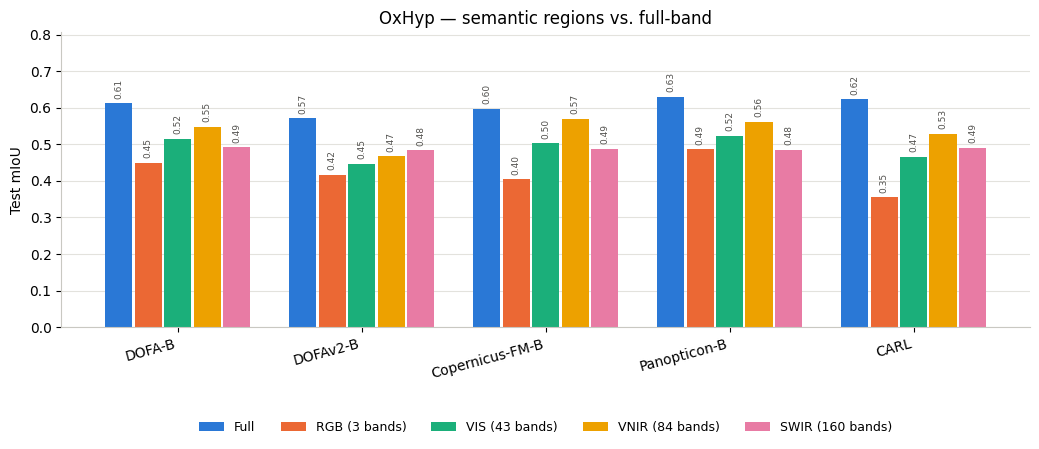

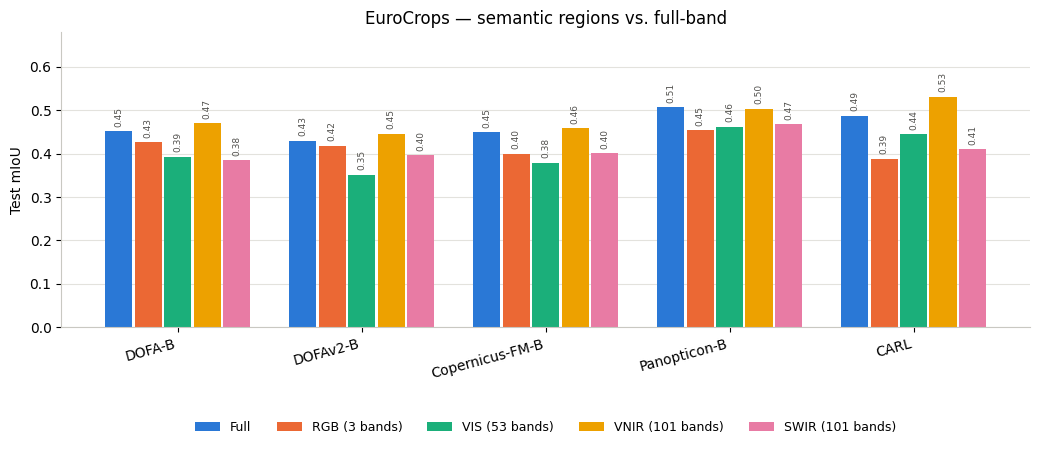

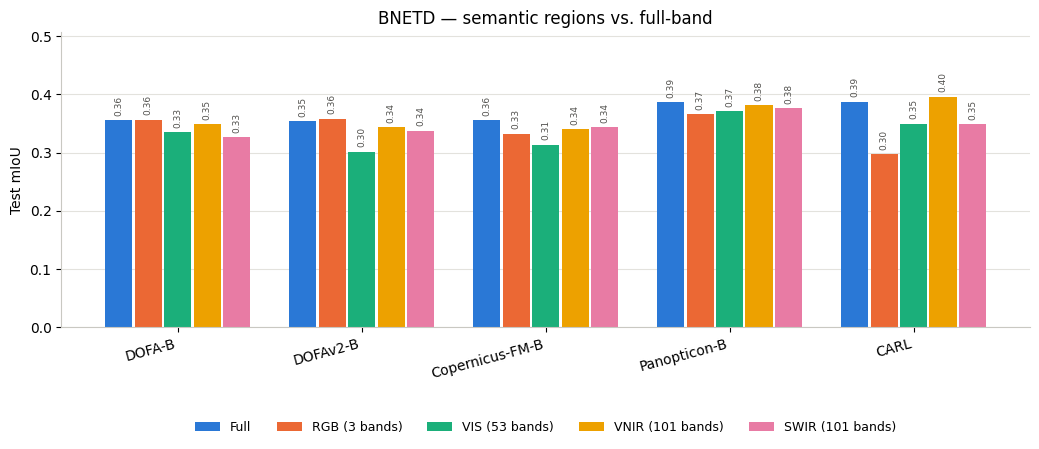

In [7]:
for task in TASKS:
    fig = plot_task_bars(results_long, task, mode="semantic", title_suffix="semantic regions vs. full-band")
    plt.show()

### Detailed tables (semantic regions)

In [8]:
def pivot_condition(df: pd.DataFrame, condition: str, metric: str = "mIoU") -> pd.DataFrame:
    subset = df[df["condition"] == condition]
    table = subset.pivot(index="backbone", columns="task", values=metric)
    row_order = [b for b in BACKBONES if b in table.index]
    col_order = [t for t in TASKS if t in table.columns]
    table = table.reindex(index=row_order, columns=col_order)
    table.index = [BACKBONE_LABELS[b] for b in table.index]
    table.columns = [TASK_LABELS[t] for t in table.columns]
    return table


def style_table(df: pd.DataFrame, caption: str):
    return (
        df.style
        .format("{:.3f}", na_rep="\u2014")
        .highlight_max(axis=0, props="font-weight:bold;background-color:#e6f4ea;")
        .set_caption(caption)
    )


for group in GROUPS:
    display(style_table(pivot_condition(results_long, group), f"{GROUP_LABELS[group]} -- test mIoU"))

,OxHyp,EuroCrops,BNETD
DOFA-B,0.612,0.452,0.356
DOFAv2-B,0.571,0.429,0.354
Copernicus-FM-B,0.597,0.449,0.356
Panopticon-B,0.630,0.507,0.387
CARL,0.624,0.488,0.387


,OxHyp,EuroCrops,BNETD
DOFA-B,0.449,0.427,0.356
DOFAv2-B,0.416,0.418,0.358
Copernicus-FM-B,0.404,0.400,0.333
Panopticon-B,0.486,0.454,0.366
CARL,0.355,0.388,0.297


,OxHyp,EuroCrops,BNETD
DOFA-B,0.515,0.392,0.335
DOFAv2-B,0.447,0.352,0.302
Copernicus-FM-B,0.503,0.379,0.313
Panopticon-B,0.523,0.462,0.371
CARL,0.466,0.445,0.350


,OxHyp,EuroCrops,BNETD
DOFA-B,0.548,0.470,0.349
DOFAv2-B,0.467,0.446,0.344
Copernicus-FM-B,0.569,0.458,0.340
Panopticon-B,0.561,0.503,0.381
CARL,0.529,0.531,0.396


,OxHyp,EuroCrops,BNETD
DOFA-B,0.492,0.385,0.326
DOFAv2-B,0.484,0.396,0.337
Copernicus-FM-B,0.488,0.401,0.343
Panopticon-B,0.485,0.468,0.376
CARL,0.490,0.410,0.349


# Part 2 — Random band subsets

Per dataset, per encoder: Full-band baseline vs. the mean of 3 independent random draws at each band
count (whiskers show the observed min–max range across the 3 seeds, not a std). Includes
**UniverSat-B** alongside the 5 `mlp_fusion_head` encoders *(different decoder/path -- ConvSegmentor,
not directly comparable to the other 5; flagged here for now, TODO: proper footnote)*.

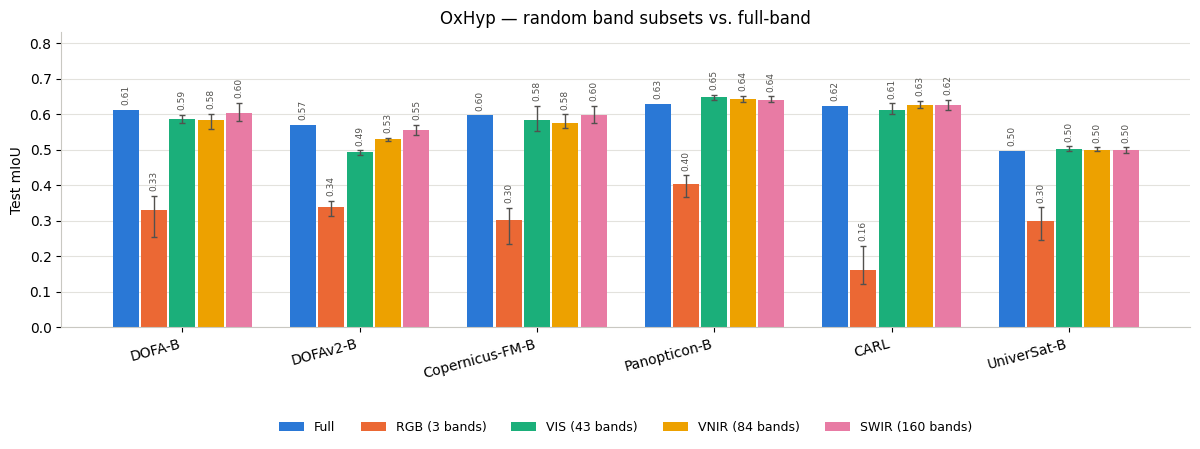

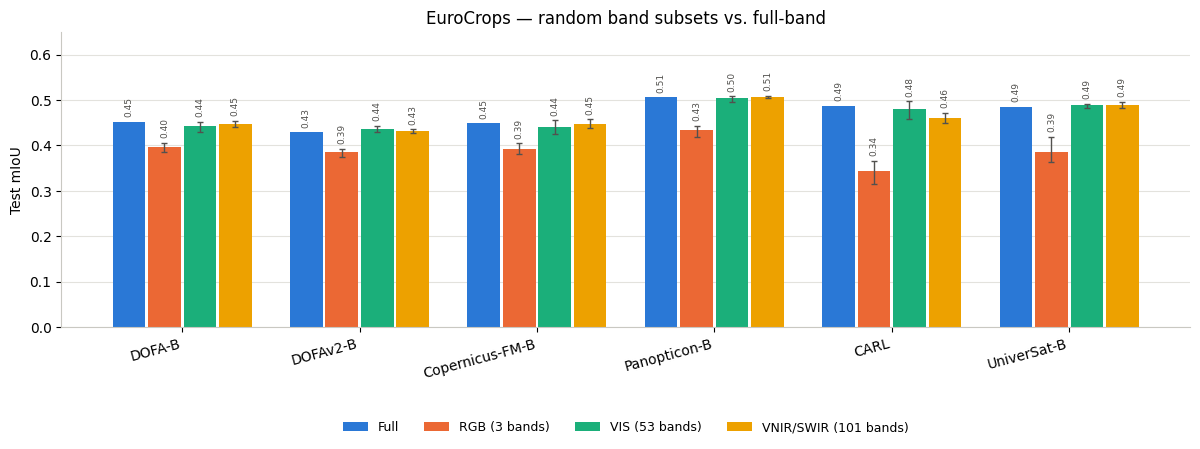

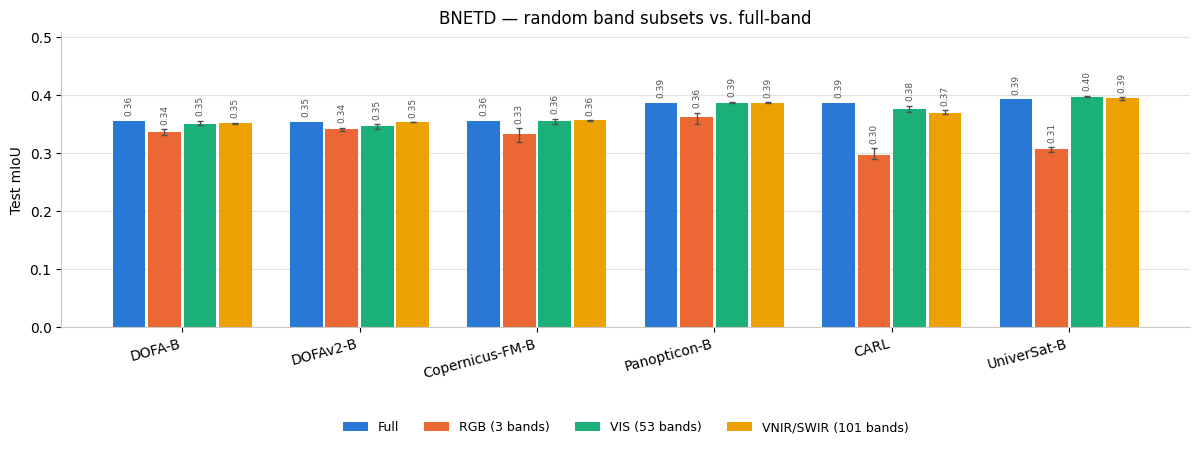

In [9]:
for task in TASKS:
    fig = plot_task_bars(
        part2_long, task, mode="random", title_suffix="random band subsets vs. full-band",
        backbones=PART2_BACKBONES, combine_equal_counts=True,
    )
    plt.show()

## Which bands were selected?

Recomputes the same deterministic seeded draws `print_random_band_overrides.py` used at submission
time (same seeds, same sampling -- `random.Random(seed).sample(...)`, so this is guaranteed to match
what was actually run) and plots each condition's selected bands along the wavelength axis. Dot color
matches the band-count category's color in the bar charts above; the two gray reference lines mark
the VIS/VNIR (700nm) and VNIR/SWIR (1000nm) boundaries used to define the semantic regions in Part 1.

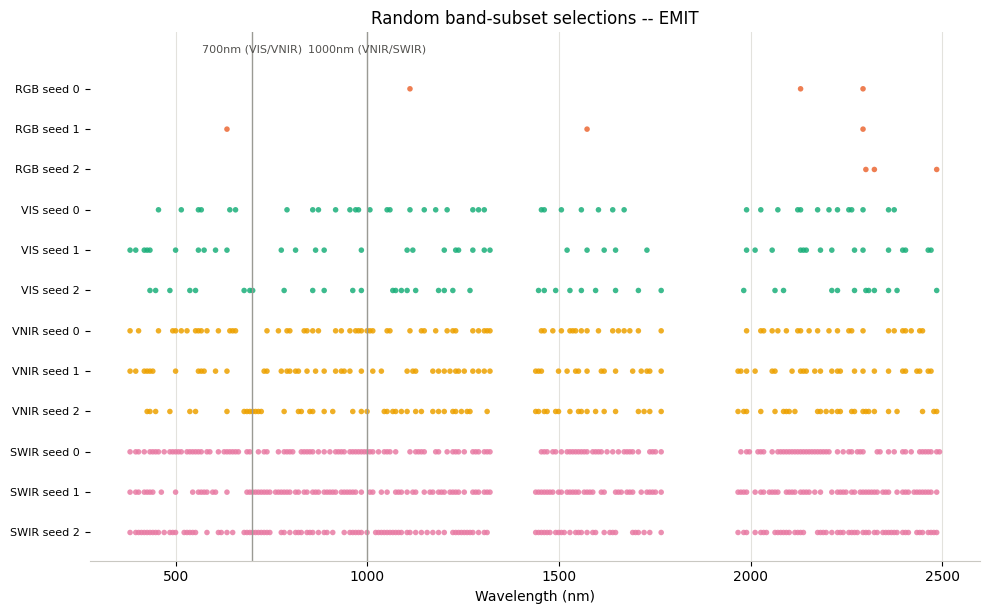

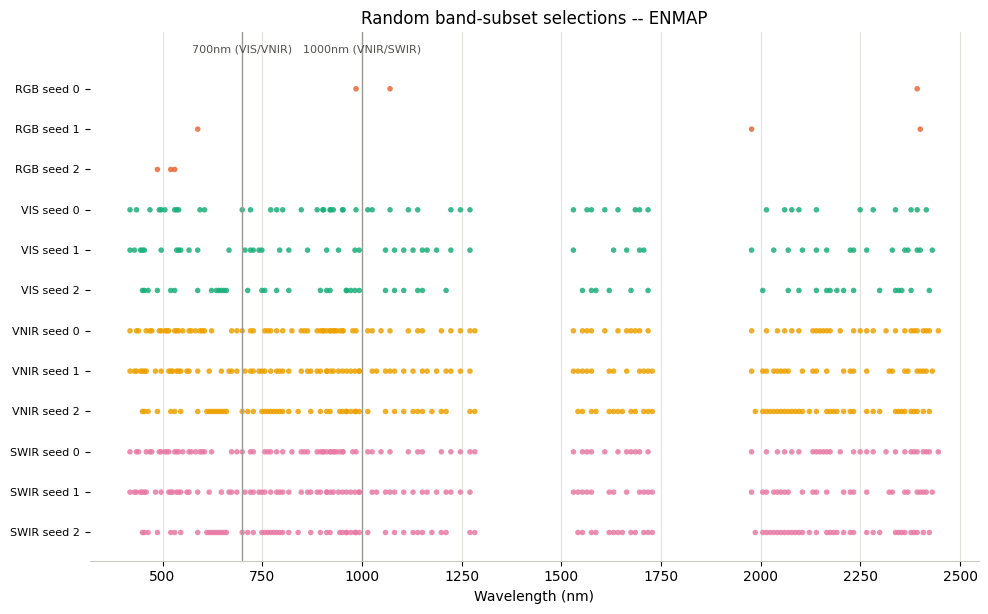

In [10]:
def plot_band_selection(sensor: str):
    rgb_indices, wavelengths = load_sensor_wavelengths(sensor)
    num_bands = len(wavelengths)

    rows_plot = []  # (label, size_label, wavelengths_selected)
    for size_label in SIZE_LABELS:
        n = group_size(size_label, rgb_indices, wavelengths)
        for seed in SEEDS:
            rng = random.Random(seed)
            indices = sorted(rng.sample(range(num_bands), n))
            rows_plot.append((f"{GROUP_LABELS[size_label]} seed {seed}", size_label, [wavelengths[i] for i in indices]))

    fig, ax = plt.subplots(figsize=(10, 0.42 * len(rows_plot) + 1.2))
    for row_i, (label, size_label, wls) in enumerate(rows_plot):
        y = len(rows_plot) - row_i
        ax.scatter(wls, [y] * len(wls), color=CONDITION_COLORS[size_label], s=16, alpha=0.85, edgecolors="none")

    ax.set_yticks(range(1, len(rows_plot) + 1))
    ax.set_yticklabels([r[0] for r in reversed(rows_plot)], fontsize=8)
    ax.set_ylim(0.3, len(rows_plot) + 1.4)

    for boundary, label in [(700, "700nm (VIS/VNIR)"), (1000, "1000nm (VNIR/SWIR)")]:
        ax.axvline(boundary, color="#9a9a94", linewidth=1)
        ax.text(boundary, len(rows_plot) + 0.9, label, fontsize=8, color=TEXT_MUTED, ha="center")

    ax.set_xlabel("Wavelength (nm)")
    ax.set_title(f"Random band-subset selections -- {sensor.upper()}")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.xaxis.grid(True, linewidth=0.8, color=GRID_COLOR)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()


for sensor in ["emit", "enmap"]:
    plot_band_selection(sensor)

# Part 3 — Semantic vs. random, matched by band count

The comparison that isolates band *count* from band *identity*: does the real region actually beat
an arbitrary same-size random subset?

In [11]:
def semantic_vs_random_by_task_size(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for task in TASKS:
        for size_label in SIZE_LABELS:
            sem = df[
                (df.task == task) & (df.condition_type == "semantic") & (df.size_label == size_label)
            ]["mIoU"].dropna()
            rand = df[
                (df.task == task) & (df.condition_type == "random") & (df.size_label == size_label)
            ]["mIoU"].dropna()
            full = df[(df.task == task) & (df.condition_type == "full")]["mIoU"].dropna()
            rows.append({
                "task": TASK_LABELS[task],
                "size": GROUP_LABELS[size_label],
                "full_mIoU": full.mean() if len(full) else None,
                "semantic_mIoU": sem.mean() if len(sem) else None,
                "random_mean_mIoU": rand.mean() if len(rand) else None,
                "random_std_mIoU": rand.std() if len(rand) else None,
                "random_max_mIoU": rand.max() if len(rand) else None,
                "semantic_minus_random_mean": (
                    (sem.mean() - rand.mean()) if len(sem) and len(rand) else None
                ),
            })
    return pd.DataFrame(rows)


summary_by_task_size = semantic_vs_random_by_task_size(results_long)
(
    summary_by_task_size.style
    .format("{:.3f}", subset=[c for c in summary_by_task_size.columns if c not in ("task", "size")], na_rep="\u2014")
    .background_gradient(cmap="RdYlGn", subset=["semantic_minus_random_mean"], vmin=-0.1, vmax=0.1)
    .set_caption("Semantic region vs. random subset at matched band count (averaged across 5 encoders)")
)

,task,size,full_mIoU,semantic_mIoU,random_mean_mIoU,random_std_mIoU,random_max_mIoU,semantic_minus_random_mean
0,OxHyp,RGB,0.606,0.422,0.307,0.093,0.428,0.115
1,OxHyp,VIS,0.606,0.491,0.584,0.056,0.654,-0.094
2,OxHyp,VNIR,0.606,0.535,0.591,0.043,0.652,-0.056
3,OxHyp,SWIR,0.606,0.488,0.604,0.034,0.650,-0.116
4,EuroCrops,RGB,0.465,0.417,0.391,0.033,0.444,0.027
5,EuroCrops,VIS,0.465,0.406,0.461,0.030,0.509,-0.055
6,EuroCrops,VNIR,0.465,0.482,0.459,0.027,0.510,0.023
7,EuroCrops,SWIR,0.465,0.412,0.459,0.028,0.510,-0.047
8,BNETD,RGB,0.368,0.342,0.334,0.023,0.370,0.008
9,BNETD,VIS,0.368,0.334,0.363,0.017,0.388,-0.029


### Same comparison, per encoder

Checks whether the semantic-beats-random pattern holds consistently across architecturally different
encoders, or is driven by one or two of them.

In [12]:
def semantic_vs_random_by_backbone(df: pd.DataFrame, task: str, size_label: str) -> pd.DataFrame:
    rows = []
    for backbone in BACKBONES:
        sub = df[(df.task == task) & (df.backbone == backbone)]
        full = sub[sub.condition_type == "full"]["mIoU"]
        sem = sub[(sub.condition_type == "semantic") & (sub.size_label == size_label)]["mIoU"]
        rand = sub[(sub.condition_type == "random") & (sub.size_label == size_label)]["mIoU"].dropna()
        rows.append({
            "backbone": BACKBONE_LABELS[backbone],
            "full_mIoU": full.iloc[0] if len(full) else None,
            "semantic_mIoU": sem.iloc[0] if len(sem) else None,
            "random_seed_scores": ", ".join(f"{v:.3f}" for v in sorted(rand)) if len(rand) else "\u2014",
            "semantic_beats_all_seeds": (
                bool(len(sem) and len(rand) == len(SEEDS) and sem.iloc[0] > rand.max())
                if len(sem) and len(rand)
                else None
            ),
        })
    return pd.DataFrame(rows)


for task in TASKS:
    for size_label in SIZE_LABELS:
        print(f"--- {TASK_LABELS[task]} / {GROUP_LABELS[size_label]} ---")
        display(semantic_vs_random_by_backbone(results_long, task, size_label))

--- OxHyp / RGB ---


,backbone,full_mIoU,semantic_mIoU,random_seed_scores,semantic_beats_all_seeds
0,DOFA-B,0.611681,0.449230,"0.255, 0.365, 0.370",True
1,DOFAv2-B,0.570644,0.416153,"0.314, 0.349, 0.357",True
2,Copernicus-FM-B,0.596740,0.403869,"0.235, 0.334, 0.337",True
3,Panopticon-B,0.629848,0.486276,"0.366, 0.417, 0.428",True
4,CARL,0.623564,0.354621,"0.121, 0.134, 0.229",True


--- OxHyp / VIS ---


,backbone,full_mIoU,semantic_mIoU,random_seed_scores,semantic_beats_all_seeds
0,DOFA-B,0.611681,0.515441,"0.576, 0.582, 0.598",False
1,DOFAv2-B,0.570644,0.447250,"0.485, 0.494, 0.498",False
2,Copernicus-FM-B,0.596740,0.502627,"0.553, 0.573, 0.624",False
3,Panopticon-B,0.629848,0.522873,"0.640, 0.653, 0.654",False
4,CARL,0.623564,0.465795,"0.600, 0.605, 0.630",False


--- OxHyp / VNIR ---


...

,backbone,full_mIoU,semantic_mIoU,random_seed_scores,semantic_beats_all_seeds
0,DOFA-B,0.355546,0.334830,"0.348, 0.348, 0.355",False
1,DOFAv2-B,0.354106,0.301542,"0.342, 0.346, 0.350",False
2,Copernicus-FM-B,0.355728,0.313435,"0.351, 0.356, 0.359",False
3,Panopticon-B,0.386601,0.370683,"0.386, 0.387, 0.388",False
4,CARL,0.387040,0.349843,"0.371, 0.377, 0.381",False


--- BNETD / VNIR ---


,backbone,full_mIoU,semantic_mIoU,random_seed_scores,semantic_beats_all_seeds
0,DOFA-B,0.355546,0.348970,"0.351, 0.352, 0.353",False
1,DOFAv2-B,0.354106,0.343557,"0.353, 0.353, 0.354",False
2,Copernicus-FM-B,0.355728,0.339905,"0.356, 0.356, 0.357",False
3,Panopticon-B,0.386601,0.380915,"0.386, 0.387, 0.388",False
4,CARL,0.387040,0.395918,"0.367, 0.368, 0.372",True


--- BNETD / SWIR ---


,backbone,full_mIoU,semantic_mIoU,random_seed_scores,semantic_beats_all_seeds
0,DOFA-B,0.355546,0.326101,"0.351, 0.352, 0.352",False
1,DOFAv2-B,0.354106,0.337108,"0.353, 0.353, 0.354",False
2,Copernicus-FM-B,0.355728,0.343255,"0.355, 0.356, 0.357",False
3,Panopticon-B,0.386601,0.375906,"0.385, 0.386, 0.387",False
4,CARL,0.387040,0.348705,"0.367, 0.369, 0.375",False


### How much should we trust "random beats semantic"?

A fair objection: with only 3 random draws per condition, a single draw could just have landed on
unusually informative bands by chance -- we wouldn't be seeing "coverage beats a narrow region", just
a lucky sample. Two things are worth separating here:

1. **The 5-encoder agreement seen above is *not* 5 independent confirmations of the random-sampling
   result.** The same 3 draws are reused across all 5 encoders (deliberately, so encoder comparisons
   are apples-to-apples -- see the explanation of the draw itself, earlier in this notebook). So "5
   encoders all show random winning" mostly tells us the pattern is architecture-independent *for
   these particular bands* -- it does **not** mean we drew 15 independent random samples. The real
   sample size for "how many different random subsets did we test" is **3 per (task, size)**, not 15.
2. What *does* distinguish "a robust effect" from "one lucky draw" is whether **all 3 seeds
   individually** tend to beat the semantic region, or whether it's really one seed doing all the
   work while the other two don't. That's directly checkable — the table below counts, per seed, how
   many of the 5 encoders it beat the semantic score for.

In [13]:
def seed_consistency_table(df: pd.DataFrame) -> pd.DataFrame:
    # For each (task, size), how many of the 5 encoders did EACH individual
    # random seed beat the semantic-region score for. If the 3 counts are close
    # together, all 3 draws behave similarly (a robust effect, not one lucky
    # draw). If they're far apart -- e.g. 5/5, 0/5, 1/5 -- a single seed is
    # doing all the work and the "random beats semantic" reading for that
    # (task, size) should be treated with more caution.
    rows = []
    for task in TASKS:
        for size_label in SIZE_LABELS:
            row = {"task": TASK_LABELS[task], "size": GROUP_LABELS[size_label]}
            seed_win_counts = []
            for seed in SEEDS:
                wins = 0
                total = 0
                for backbone in BACKBONES:
                    sub = df[(df.task == task) & (df.backbone == backbone)]
                    sem = sub[(sub.condition_type == "semantic") & (sub.size_label == size_label)]["mIoU"]
                    r = sub[
                        (sub.condition_type == "random")
                        & (sub.size_label == size_label)
                        & (sub.seed == seed)
                    ]["mIoU"]
                    if len(sem) and len(r):
                        total += 1
                        if r.iloc[0] > sem.iloc[0]:
                            wins += 1
                row[f"seed{seed}_beats_semantic"] = f"{wins}/{total}"
                seed_win_counts.append(wins)
            row["spread_across_seeds"] = max(seed_win_counts) - min(seed_win_counts)
            rows.append(row)
    return pd.DataFrame(rows)


consistency_table = seed_consistency_table(results_long)
(
    consistency_table.style
    .background_gradient(cmap="RdYlGn_r", subset=["spread_across_seeds"], vmin=0, vmax=5)
    .set_caption(
        "Per-seed win count (out of 5 encoders) -- a small spread_across_seeds means all 3 "
        "draws agree; a large one means one seed is driving the result"
    )
)

,task,size,seed0_beats_semantic,seed1_beats_semantic,seed2_beats_semantic,spread_across_seeds
0,OxHyp,RGB,0/5,0/5,0/5,0
1,OxHyp,VIS,5/5,5/5,5/5,0
2,OxHyp,VNIR,5/5,4/5,5/5,1
3,OxHyp,SWIR,5/5,5/5,5/5,0
4,EuroCrops,RGB,0/5,1/5,0/5,1
5,EuroCrops,VIS,5/5,5/5,5/5,0
6,EuroCrops,VNIR,1/5,2/5,1/5,1
7,EuroCrops,SWIR,5/5,5/5,5/5,0
8,BNETD,RGB,2/5,2/5,0/5,2
9,BNETD,VIS,5/5,5/5,5/5,0


## Takeaways

**RGB (3 bands) is the one size where the curated region clearly wins.** The real RGB bands beat
*all 3* random 3-band draws in 11/15 (task, encoder) combinations, and were never far behind in the
rest -- consistent with the earlier per-class OxHyp finding (goethite/hematite favoring VNIR,
kaolinite favoring SWIR) that these encoders do use *which* bands they're given, not just how many.
At this band count the effect is large and easy to see: three specific, well-chosen bands reliably
beat three arbitrary ones.

**At VIS/VNIR/SWIR sizes (43-160 bands), the pattern flips.** The curated contiguous region beat all
3 random draws in only 4/45 combinations -- for most (task, encoder) pairs, an arbitrary scattered
sample of the *same band count* matched or beat the "correct" contiguous region, and did so
consistently across architecturally different encoders (not one outlier backbone). This isn't
evidence against wavelength conditioning being real -- RGB and the per-class mineral result already
argue it is -- but it does complicate the simple "the model finds the single best contiguous region"
story. A likely explanation, visible in the "which bands were selected" plot above: bands *within* a
narrow contiguous region (e.g. EMIT's 84-band VNIR slice) are highly correlated with their neighbors,
so a semantic region of N bands may carry substantially less *unique* spectral information than N
bands scattered across the whole 380-2500nm range, even when the semantic region is, band-for-band,
the more physically diagnostic one. Coverage *breadth* appears to matter as much as -- or more than
-- landing in the theoretically best single region, once the subset is large enough to matter.

**Caveat**: this is 3 random seeds per condition -- enough to see a large, consistent effect (as with
RGB) but not enough to rule out a smaller true semantic-region advantage at the VIS/VNIR/SWIR sizes
being swamped by seed-to-seed variance. `random_std_mIoU` in the Part 3 summary table gives a rough
sense of that spread per condition.